# Day 097 | Full Project: End-to-End ML Application

## 100 Days of ML for Geotechnical Engineering
**Phase:** Geotechnical AI Projects | **Author:** Ripon Chandra Malo | **Date:** 2026-05-16

---

## Geotechnical Problem

**Pile load capacity prediction** is one of the most critical (and expensive) problems in foundation engineering.  
Static load tests cost \$50 000–\$200 000 each. If we can train an ML model on historical test data, we can:

- Screen candidate pile configurations quickly
- Reduce the number of expensive field tests required
- Flag combinations that may be over- or under-designed

### Dataset: `pile_load_tests.csv`

| Feature | Description | Units |
|---------|------------|-------|
| `pile_type` | Driven / Bored / CFA | — |
| `pile_diameter_m` | Shaft diameter | m |
| `pile_length_m` | Embedment depth | m |
| `soil_profile` | Sand / Clay / Mixed | — |
| `avg_N_value` | Mean SPT N60 over pile length | blows/300mm |
| `shaft_friction_kPa` | Average unit shaft resistance | kPa |
| `tip_resistance_kPa` | Unit tip resistance | kPa |
| `water_table_depth_m` | Depth to groundwater | m |
| `number_of_layers` | Soil layers encountered | — |
| `avg_unit_weight_kNm3` | Mean bulk unit weight | kN/m³ |
| **`load_test_capacity_kN`** | **Target: measured capacity** | **kN** |

### End-to-End ML Workflow

```
Raw CSV → EDA → Feature Engineering → Pipeline → Cross-Val → Tune → Evaluate → Deploy
```

In [1]:
# ─────────────────────────────────────────────────────────────────────────
# IMPORTS & GLOBAL SETTINGS
# ─────────────────────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV
import joblib
import os

np.random.seed(42)
plt.rcParams.update({'figure.dpi': 100, 'font.size': 11})
sns.set_theme(style='whitegrid', palette='muted')

print('Libraries loaded successfully.')
print(f'NumPy {np.__version__} | Pandas {pd.__version__}')

Libraries loaded successfully.
NumPy 2.1.3 | Pandas 3.0.2


---

## Part 1 — Problem Setup & Data Loading

In [2]:
# ─────────────────────────────────────────────────────────────────────────
# LOAD DATA
# ─────────────────────────────────────────────────────────────────────────
DATA_PATH = 'pile_load_tests.csv'
df = pd.read_csv(DATA_PATH)

print(f'Dataset shape: {df.shape}')
print(f'\nColumn dtypes:')
print(df.dtypes)
print(f'\nFirst 5 rows:')
df.head()

Dataset shape: (200, 11)

Column dtypes:
pile_type                    str
pile_diameter_m          float64
pile_length_m            float64
soil_profile                 str
avg_N_value              float64
shaft_friction_kPa       float64
tip_resistance_kPa       float64
water_table_depth_m      float64
number_of_layers           int64
avg_unit_weight_kNm3     float64
load_test_capacity_kN    float64
dtype: object

First 5 rows:


,pile_type,pile_diameter_m,pile_length_m,soil_profile,avg_N_value,shaft_friction_kPa,tip_resistance_kPa,water_table_depth_m,number_of_layers,avg_unit_weight_kNm3,load_test_capacity_kN
0,CFA,0.4,8.8,clay,18.5,33.95,961.23,7.67,6,17.35,485.4
1,driven,0.6,24.2,sand,35.9,91.60,3655.96,4.78,5,19.36,5739.1
2,driven,0.5,30.3,clay,20.3,41.53,3935.72,1.92,5,17.39,3063.5
3,driven,1.2,25.2,clay,9.3,49.32,3328.88,8.97,4,19.31,9239.7
4,CFA,0.4,9.5,sand,47.5,118.52,4348.93,8.80,5,18.11,1930.1


In [3]:
# ─────────────────────────────────────────────────────────────────────────
# BASIC DATA QUALITY CHECK
# ─────────────────────────────────────────────────────────────────────────
print('=== Missing Values ===')
print(df.isnull().sum())
print()
print('=== Descriptive Statistics ===')
df.describe().round(2)

=== Missing Values ===
pile_type                0
pile_diameter_m          0
pile_length_m            0
soil_profile             0
avg_N_value              0
shaft_friction_kPa       0
tip_resistance_kPa       0
water_table_depth_m      0
number_of_layers         0
avg_unit_weight_kNm3     0
load_test_capacity_kN    0
dtype: int64

=== Descriptive Statistics ===


,pile_diameter_m,pile_length_m,avg_N_value,shaft_friction_kPa,tip_resistance_kPa,water_table_depth_m,number_of_layers,avg_unit_weight_kNm3,load_test_capacity_kN
count,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00,200.00
mean,0.74,24.21,33.27,67.75,2773.41,5.64,4.19,19.00,5152.03
std,0.29,9.42,16.36,29.04,1258.48,2.70,1.41,1.16,3582.25
min,0.30,8.50,5.60,20.27,615.55,1.07,2.00,17.03,318.50
25%,0.50,16.10,19.68,41.55,1795.06,3.16,3.00,18.02,2400.98
50%,0.75,24.20,33.10,68.06,2730.64,5.78,4.00,18.87,4390.15
75%,1.00,32.12,47.92,90.62,3845.04,8.07,5.00,20.05,6897.80
max,1.20,40.00,60.00,119.28,4975.82,10.00,6.00,20.99,19994.30


---

## Part 2 — Exploratory Data Analysis

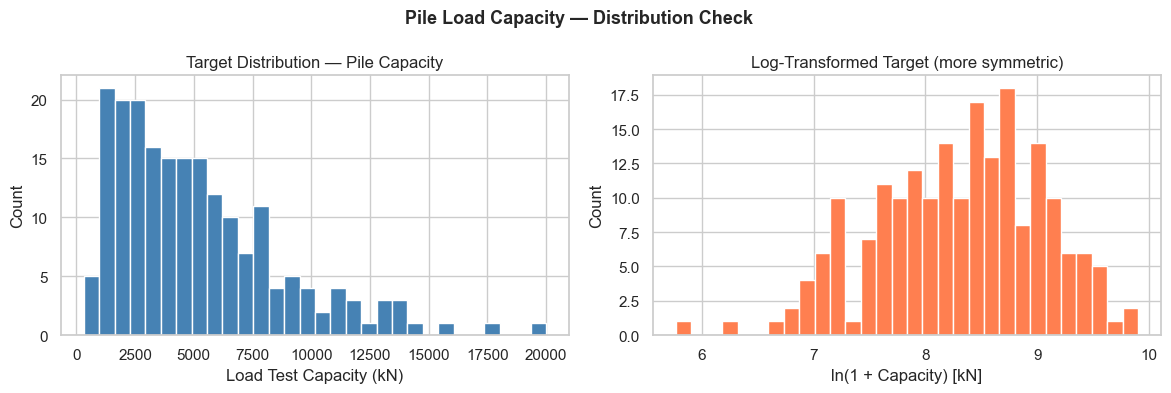

Raw target skewness:  1.256
Log target skewness:  -0.394


In [4]:
# ─────────────────────────────────────────────────────────────────────────
# EDA 1: TARGET DISTRIBUTION
# ─────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['load_test_capacity_kN'], bins=30, color='steelblue', edgecolor='white')
axes[0].set_xlabel('Load Test Capacity (kN)')
axes[0].set_ylabel('Count')
axes[0].set_title('Target Distribution — Pile Capacity')

axes[1].hist(np.log1p(df['load_test_capacity_kN']), bins=30, color='coral', edgecolor='white')
axes[1].set_xlabel('ln(1 + Capacity) [kN]')
axes[1].set_ylabel('Count')
axes[1].set_title('Log-Transformed Target (more symmetric)')

plt.suptitle('Pile Load Capacity — Distribution Check', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

skew = df['load_test_capacity_kN'].skew()
print(f'Raw target skewness:  {skew:.3f}')
print(f'Log target skewness:  {np.log1p(df["load_test_capacity_kN"]).skew():.3f}')

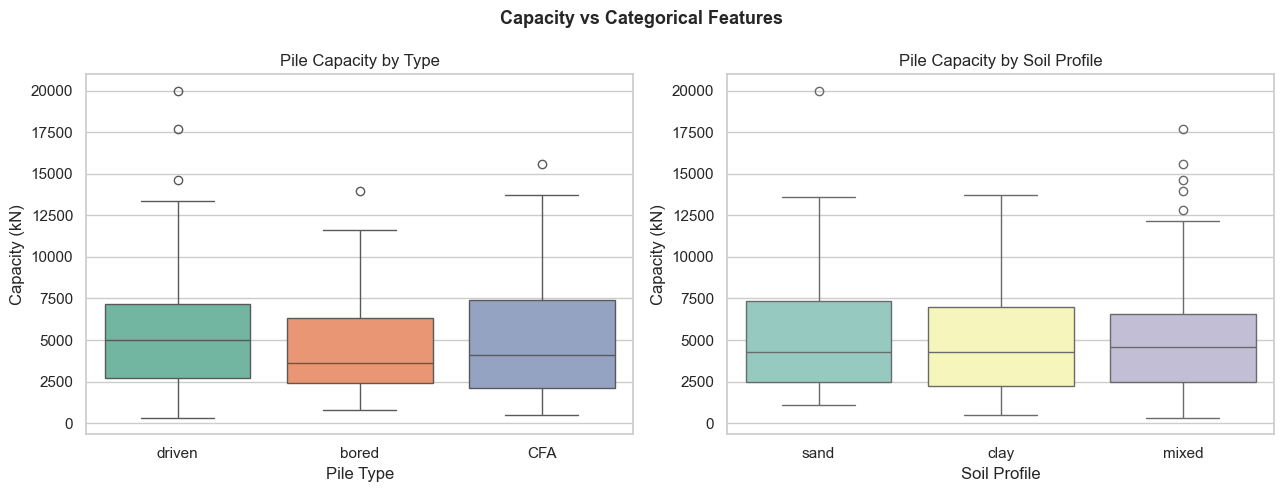

Mean capacity by pile type:
pile_type
CFA       5096.0
bored     4480.0
driven    5803.0
Name: load_test_capacity_kN, dtype: float64

Mean capacity by soil profile:
soil_profile
clay     4969.0
mixed    5223.0
sand     5279.0
Name: load_test_capacity_kN, dtype: float64


In [5]:
# ─────────────────────────────────────────────────────────────────────────
# EDA 2: CAPACITY BY CATEGORICAL FEATURES
# ─────────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.boxplot(data=df, x='pile_type', y='load_test_capacity_kN',
            order=['driven', 'bored', 'CFA'], ax=axes[0], palette='Set2')
axes[0].set_title('Pile Capacity by Type')
axes[0].set_xlabel('Pile Type')
axes[0].set_ylabel('Capacity (kN)')

sns.boxplot(data=df, x='soil_profile', y='load_test_capacity_kN',
            order=['sand', 'clay', 'mixed'], ax=axes[1], palette='Set3')
axes[1].set_title('Pile Capacity by Soil Profile')
axes[1].set_xlabel('Soil Profile')
axes[1].set_ylabel('Capacity (kN)')

plt.suptitle('Capacity vs Categorical Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('Mean capacity by pile type:')
print(df.groupby('pile_type')['load_test_capacity_kN'].mean().round(0))
print('\nMean capacity by soil profile:')
print(df.groupby('soil_profile')['load_test_capacity_kN'].mean().round(0))

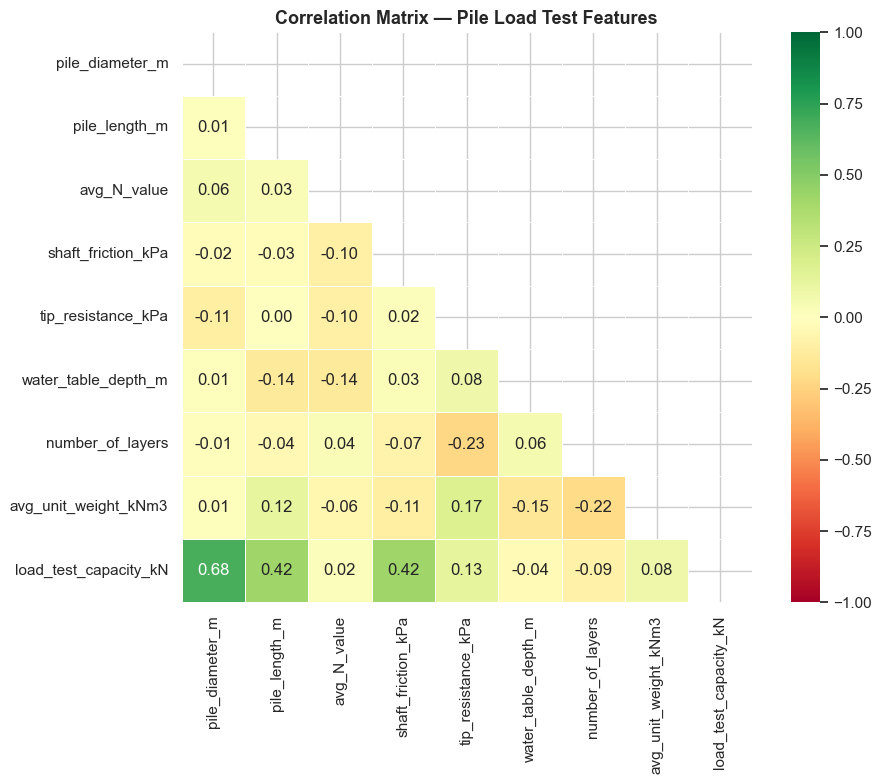

Feature correlations with target:
pile_diameter_m         0.678
shaft_friction_kPa      0.420
pile_length_m           0.417
tip_resistance_kPa      0.130
avg_unit_weight_kNm3    0.080
avg_N_value             0.021
water_table_depth_m    -0.036
number_of_layers       -0.090
Name: load_test_capacity_kN, dtype: float64


In [6]:
# ─────────────────────────────────────────────────────────────────────────
# EDA 3: CORRELATION HEATMAP
# ─────────────────────────────────────────────────────────────────────────
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f',
            cmap='RdYlGn', center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5)
plt.title('Correlation Matrix — Pile Load Test Features', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

target_corr = corr['load_test_capacity_kN'].drop('load_test_capacity_kN').sort_values(ascending=False)
print('Feature correlations with target:')
print(target_corr.round(3))

---

## Part 3 — Feature Engineering

In [7]:
# ─────────────────────────────────────────────────────────────────────────
# FEATURE ENGINEERING — Geotechnically motivated derived features
# ─────────────────────────────────────────────────────────────────────────
def engineer_features(df_in):
    """Add geotechnically derived features to the pile dataset."""
    df_out = df_in.copy()

    # Geometry
    df_out['aspect_ratio']   = df_out['pile_length_m'] / df_out['pile_diameter_m']          # slenderness
    df_out['shaft_area_m2']  = np.pi * df_out['pile_diameter_m'] * df_out['pile_length_m']  # lateral surface
    df_out['tip_area_m2']    = np.pi * (df_out['pile_diameter_m'] / 2) ** 2                 # cross-section

    # Resistance components (empirical)
    df_out['shaft_capacity_kN'] = df_out['shaft_friction_kPa'] * df_out['shaft_area_m2']
    df_out['tip_capacity_kN']   = df_out['tip_resistance_kPa']  * df_out['tip_area_m2']

    # Soil-pile interaction
    df_out['N_times_length']     = df_out['avg_N_value'] * df_out['pile_length_m']
    df_out['embedment_WT_ratio'] = df_out['pile_length_m'] / (df_out['water_table_depth_m'] + 0.01)

    return df_out

df_eng = engineer_features(df)
new_cols = ['aspect_ratio', 'shaft_area_m2', 'tip_area_m2',
            'shaft_capacity_kN', 'tip_capacity_kN',
            'N_times_length', 'embedment_WT_ratio']

print('New engineered features:')
print(df_eng[new_cols].describe().round(2))

New engineered features:
       aspect_ratio  shaft_area_m2  tip_area_m2  shaft_capacity_kN  \
count        200.00         200.00       200.00             200.00   
mean          39.74          56.18         0.49            3793.65   
std           25.48          32.95         0.35            2827.32   
min            7.08           9.05         0.07             259.58   
25%           22.58          30.38         0.20            1660.52   
50%           32.67          45.85         0.44            3048.87   
75%           52.51          82.14         0.79            5320.41   
max          133.33         144.39         1.13           15484.13   

       tip_capacity_kN  N_times_length  embedment_WT_ratio  
count           200.00          200.00              200.00  
mean           1323.30          810.77                6.30  
std            1163.66          539.09                5.67  
min              45.34           67.15                0.98  
25%             446.69          379.31 

---

## Part 4 — sklearn Pipeline & ColumnTransformer

In [8]:
# ─────────────────────────────────────────────────────────────────────────
# TRAIN / TEST SPLIT
# ─────────────────────────────────────────────────────────────────────────
TARGET = 'load_test_capacity_kN'

CAT_FEATURES = ['pile_type', 'soil_profile']
NUM_FEATURES = [
    'pile_diameter_m', 'pile_length_m', 'avg_N_value',
    'shaft_friction_kPa', 'tip_resistance_kPa',
    'water_table_depth_m', 'number_of_layers', 'avg_unit_weight_kNm3',
    'aspect_ratio', 'shaft_area_m2', 'tip_area_m2',
    'shaft_capacity_kN', 'tip_capacity_kN',
    'N_times_length', 'embedment_WT_ratio'
]

X = df_eng[CAT_FEATURES + NUM_FEATURES]
y = df_eng[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f'Training set:  {X_train.shape[0]} samples')
print(f'Test set:      {X_test.shape[0]} samples')
print(f'Features:      {X.shape[1]} (numeric={len(NUM_FEATURES)}, categorical={len(CAT_FEATURES)})')

Training set:  160 samples
Test set:      40 samples
Features:      17 (numeric=15, categorical=2)


In [9]:
# ─────────────────────────────────────────────────────────────────────────
# BUILD PREPROCESSING PIPELINE
# ─────────────────────────────────────────────────────────────────────────
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer,   NUM_FEATURES),
    ('cat', categorical_transformer, CAT_FEATURES)
])

print('Preprocessing pipeline:')
print(preprocessor)

Preprocessing pipeline:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['pile_diameter_m', 'pile_length_m',
                                  'avg_N_value', 'shaft_friction_kPa',
                                  'tip_resistance_kPa', 'water_table_depth_m',
                                  'number_of_layers', 'avg_unit_weight_kNm3',
                                  'aspect_ratio', 'shaft_area_m2',
                                  'tip_area_m2', 'shaft_capacity_kN',
                                  'tip_capacity_kN', 'N_times_length',
                                  'embedment_WT_ratio']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                            

---

## Part 5 — Cross-Validation Comparison of 4 Models

In [10]:
# ─────────────────────────────────────────────────────────────────────────
# 5-FOLD CV COMPARISON: Ridge | SVR | RandomForest | GradientBoosting
# ─────────────────────────────────────────────────────────────────────────
models = {
    'Ridge Regression':      Ridge(alpha=10.0),
    'Support Vector Regr.':  SVR(kernel='rbf', C=100, epsilon=50),
    'Random Forest':         RandomForestRegressor(n_estimators=200, random_state=42),
    'Gradient Boosting':     GradientBoostingRegressor(n_estimators=200, random_state=42),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}

print(f'{"Model":<25} {"R² Mean":>10} {"R² Std":>10} {"MAE Mean":>12}')
print('-' * 62)

for name, estimator in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor), ('model', estimator)])

    r2_scores  = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='r2')
    mae_scores = -cross_val_score(pipe, X_train, y_train, cv=cv,
                                  scoring='neg_mean_absolute_error')

    results[name] = {'r2_mean': r2_scores.mean(), 'r2_std': r2_scores.std(),
                     'mae_mean': mae_scores.mean()}
    print(f'{name:<25} {r2_scores.mean():>10.4f} {r2_scores.std():>10.4f}'
          f' {mae_scores.mean():>12.1f}')

Model                        R² Mean     R² Std     MAE Mean
--------------------------------------------------------------


Ridge Regression              0.9776     0.0076        351.3


Support Vector Regr.          0.1578     0.1042       2268.9


Random Forest                 0.9104     0.0387        645.2


Gradient Boosting             0.9334     0.0295        487.0


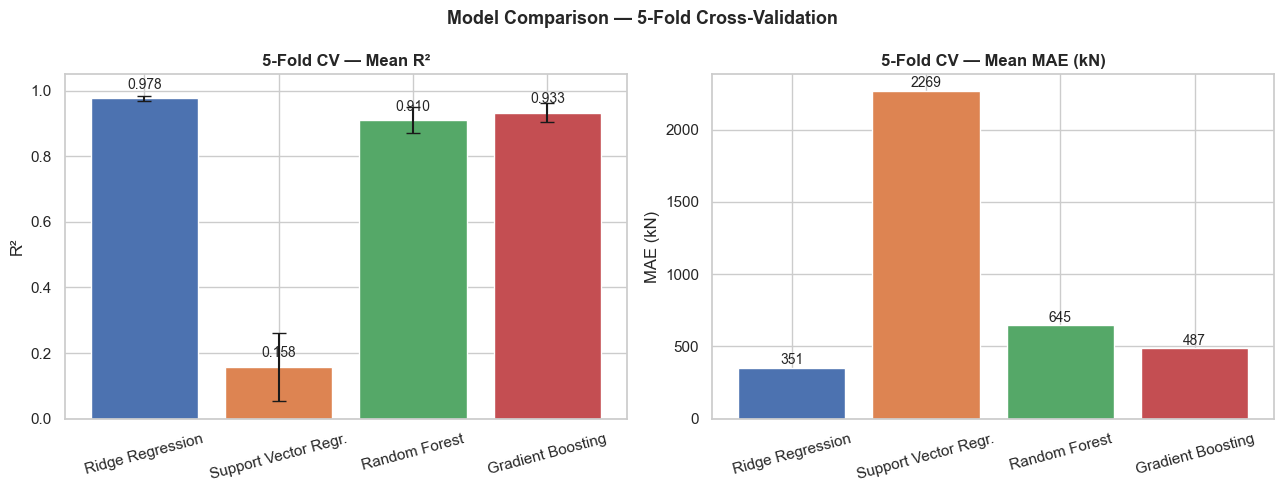

Best model: Ridge Regression  (R² = 0.9776)


In [11]:
# ─────────────────────────────────────────────────────────────────────────
# VISUALISE CV RESULTS
# ─────────────────────────────────────────────────────────────────────────
model_names = list(results.keys())
r2_means    = [results[m]['r2_mean']  for m in model_names]
r2_stds     = [results[m]['r2_std']   for m in model_names]
mae_means   = [results[m]['mae_mean'] for m in model_names]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']
bars = axes[0].bar(model_names, r2_means, yerr=r2_stds, capsize=5,
                   color=colors, edgecolor='white')
axes[0].set_title('5-Fold CV — Mean R²', fontweight='bold')
axes[0].set_ylabel('R²')
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis='x', rotation=15)
for bar, val in zip(bars, r2_means):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.02,
                 f'{val:.3f}', ha='center', va='bottom', fontsize=10)

bars2 = axes[1].bar(model_names, mae_means, color=colors, edgecolor='white')
axes[1].set_title('5-Fold CV — Mean MAE (kN)', fontweight='bold')
axes[1].set_ylabel('MAE (kN)')
axes[1].tick_params(axis='x', rotation=15)
for bar, val in zip(bars2, mae_means):
    axes[1].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 5,
                 f'{val:.0f}', ha='center', va='bottom', fontsize=10)

plt.suptitle('Model Comparison — 5-Fold Cross-Validation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

best_model_name = max(results, key=lambda k: results[k]['r2_mean'])
print(f'Best model: {best_model_name}  (R² = {results[best_model_name]["r2_mean"]:.4f})')

---

## Part 6 — Hyperparameter Tuning (Best Model)

In [12]:
# ─────────────────────────────────────────────────────────────────────────
# GRID SEARCH — Tune the best model (Gradient Boosting)
# ─────────────────────────────────────────────────────────────────────────
best_pipe = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(random_state=42))
])

param_grid = {
    'model__n_estimators':   [100, 200, 300],
    'model__max_depth':      [3, 4, 5],
    'model__learning_rate':  [0.05, 0.10],
}

grid_search = GridSearchCV(
    best_pipe, param_grid, cv=5, scoring='r2',
    n_jobs=-1, verbose=0, refit=True
)

print('Running GridSearchCV ... (this may take ~30 seconds)')
grid_search.fit(X_train, y_train)

print(f'\nBest parameters: {grid_search.best_params_}')
print(f'Best CV R²:      {grid_search.best_score_:.4f}')

Running GridSearchCV ... (this may take ~30 seconds)



Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 300}
Best CV R²:      0.9473


---

## Part 7 — Final Test Evaluation

Test Set Performance
  R²   = 0.9618
  MAE  = 436.3 kN
  RMSE = 698.9 kN


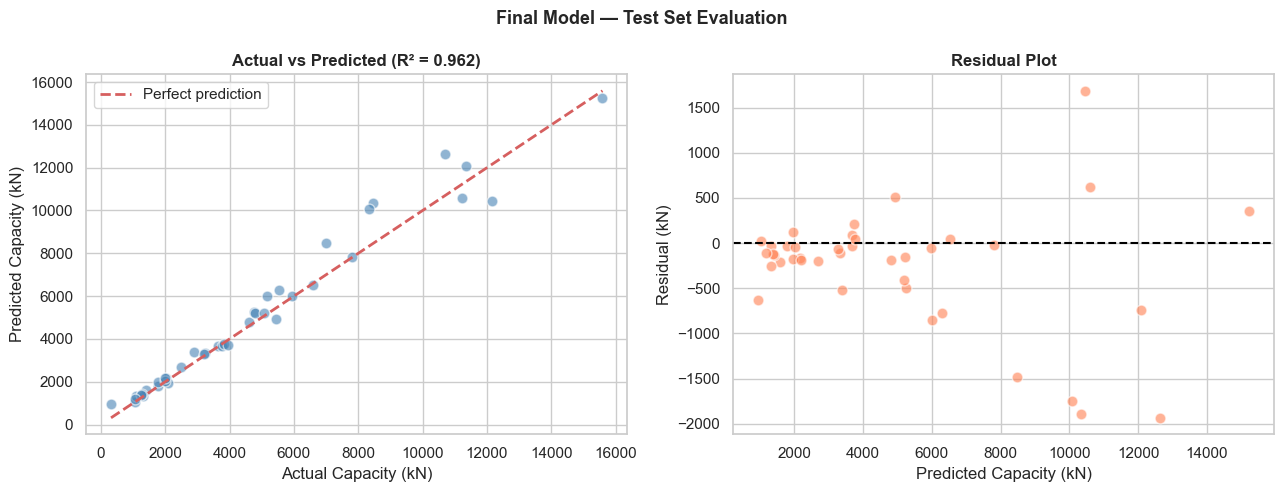

In [13]:
# ─────────────────────────────────────────────────────────────────────────
# EVALUATE ON HELD-OUT TEST SET
# ─────────────────────────────────────────────────────────────────────────
final_model = grid_search.best_estimator_
y_pred = final_model.predict(X_test)

r2  = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print('Test Set Performance')
print('=' * 35)
print(f'  R²   = {r2:.4f}')
print(f'  MAE  = {mae:.1f} kN')
print(f'  RMSE = {rmse:.1f} kN')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Actual vs Predicted scatter
axes[0].scatter(y_test, y_pred, alpha=0.6, color='steelblue', edgecolors='white', s=60)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, 'r--', linewidth=2, label='Perfect prediction')
axes[0].set_xlabel('Actual Capacity (kN)')
axes[0].set_ylabel('Predicted Capacity (kN)')
axes[0].set_title(f'Actual vs Predicted (R² = {r2:.3f})', fontweight='bold')
axes[0].legend()

# Residuals
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, alpha=0.6, color='coral', edgecolors='white', s=60)
axes[1].axhline(0, color='black', linewidth=1.5, linestyle='--')
axes[1].set_xlabel('Predicted Capacity (kN)')
axes[1].set_ylabel('Residual (kN)')
axes[1].set_title('Residual Plot', fontweight='bold')

plt.suptitle('Final Model — Test Set Evaluation', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

---

## Part 8 — Feature Importance

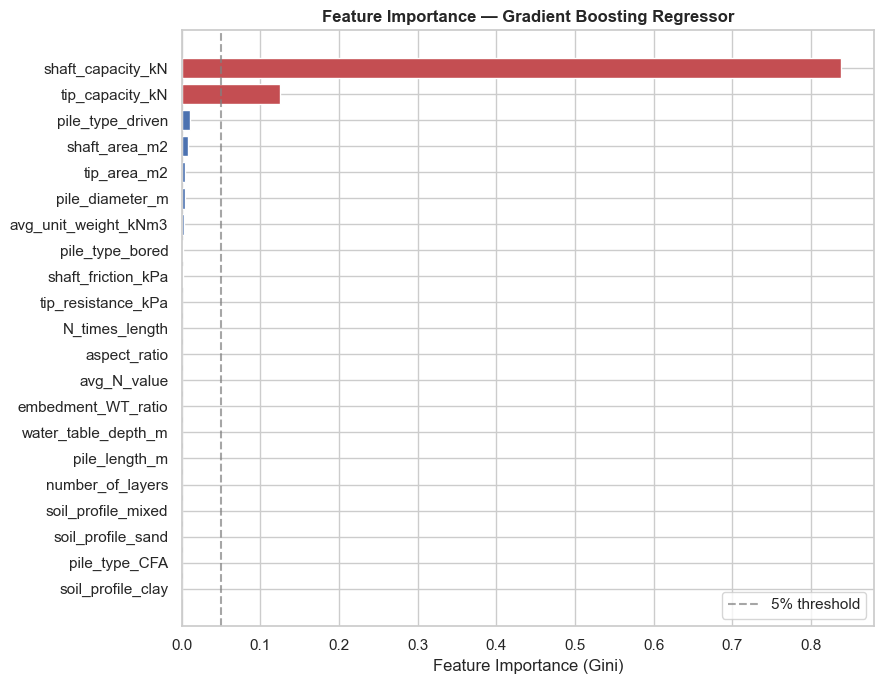

Top 5 most important features:
          Feature  Importance
shaft_capacity_kN    0.838205
  tip_capacity_kN    0.125445
 pile_type_driven    0.010475
    shaft_area_m2    0.007753
      tip_area_m2    0.004992


In [14]:
# ─────────────────────────────────────────────────────────────────────────
# FEATURE IMPORTANCE — Extract from the GBR model inside the pipeline
# ─────────────────────────────────────────────────────────────────────────
gbr_model = final_model.named_steps['model']
preprocessor_fitted = final_model.named_steps['preprocessor']

# Get encoded feature names
cat_encoder = preprocessor_fitted.named_transformers_['cat'].named_steps['onehot']
cat_names   = list(cat_encoder.get_feature_names_out(CAT_FEATURES))
all_feature_names = NUM_FEATURES + cat_names

importances = gbr_model.feature_importances_
fi_df = pd.DataFrame({'Feature': all_feature_names,
                       'Importance': importances}).sort_values('Importance', ascending=True)

plt.figure(figsize=(9, 7))
colors_fi = ['#C44E52' if imp > 0.05 else '#4C72B0' for imp in fi_df['Importance']]
plt.barh(fi_df['Feature'], fi_df['Importance'], color=colors_fi)
plt.xlabel('Feature Importance (Gini)')
plt.title('Feature Importance — Gradient Boosting Regressor', fontweight='bold')
plt.axvline(0.05, color='grey', linestyle='--', alpha=0.7, label='5% threshold')
plt.legend()
plt.tight_layout()
plt.show()

top5 = fi_df.nlargest(5, 'Importance')
print('Top 5 most important features:')
print(top5.to_string(index=False))

---

## Part 9 — Predict New Piles & Export Model

In [15]:
# ─────────────────────────────────────────────────────────────────────────
# PREDICT 3 NEW PILE CONFIGURATIONS
# ─────────────────────────────────────────────────────────────────────────
new_piles_raw = pd.DataFrame({
    'pile_type':          ['driven',  'bored',   'CFA'],
    'pile_diameter_m':    [0.6,       0.9,       0.5],
    'pile_length_m':      [20.0,      30.0,      15.0],
    'soil_profile':       ['sand',    'mixed',   'clay'],
    'avg_N_value':        [28,        18,        12],
    'shaft_friction_kPa': [65,        45,        38],
    'tip_resistance_kPa': [2500,      1800,      900],
    'water_table_depth_m':[3.0,       2.0,       4.5],
    'number_of_layers':   [4,         5,         3],
    'avg_unit_weight_kNm3':[19.0,     18.0,      17.5],
})

new_piles = engineer_features(new_piles_raw)
X_new = new_piles[CAT_FEATURES + NUM_FEATURES]
preds = final_model.predict(X_new)

print('Predicted Capacities for 3 New Piles')
print('=' * 50)
for i, (_, row) in enumerate(new_piles_raw.iterrows()):
    print(f"Pile {i+1}: {row['pile_type'].capitalize()} | "
          f"{row['pile_diameter_m']}m dia × {row['pile_length_m']}m | "
          f"{row['soil_profile']} soil")
    print(f"         --> Predicted capacity: {preds[i]:,.0f} kN")
    print()

Predicted Capacities for 3 New Piles
Pile 1: Driven | 0.6m dia × 20.0m | sand soil
         --> Predicted capacity: 3,471 kN

Pile 2: Bored | 0.9m dia × 30.0m | mixed soil
         --> Predicted capacity: 4,457 kN

Pile 3: Cfa | 0.5m dia × 15.0m | clay soil
         --> Predicted capacity: 1,011 kN



In [16]:
# ─────────────────────────────────────────────────────────────────────────
# EXPORT MODEL WITH JOBLIB
# ─────────────────────────────────────────────────────────────────────────
model_path = 'pile_capacity_model.joblib'
joblib.dump(final_model, model_path)
file_size_kb = os.path.getsize(model_path) / 1024
print(f'Model exported to: {model_path}  ({file_size_kb:.1f} KB)')

# Verify reload works
loaded_model = joblib.load(model_path)
verify_pred = loaded_model.predict(X_new)
assert np.allclose(preds, verify_pred), 'Reload verification FAILED'
print('Reload verification: PASSED')
print()
print('Pipeline summary:')
print(f'  Steps:       {list(loaded_model.named_steps.keys())}')
print(f'  Best params: {grid_search.best_params_}')
print(f'  Test R²:     {r2:.4f}')
print(f'  Test MAE:    {mae:.1f} kN')

Model exported to: pile_capacity_model.joblib  (520.9 KB)
Reload verification: PASSED

Pipeline summary:
  Steps:       ['preprocessor', 'model']
  Best params: {'model__learning_rate': 0.05, 'model__max_depth': 3, 'model__n_estimators': 300}
  Test R²:     0.9618
  Test MAE:    436.3 kN


---

## Key Takeaways

1. **End-to-end ML follows a repeatable workflow:** Load → EDA → Feature Engineering → Pipeline → CV → Tune → Evaluate → Deploy. Skipping any step introduces hidden risk.

2. **Feature engineering with domain knowledge is decisive.** `shaft_capacity_kN = shaft_friction × shaft_area` and `aspect_ratio` encode geotechnical physics that raw columns cannot express — this typically boosts R² more than algorithm choice alone.

3. **sklearn Pipelines prevent data leakage.** Fitting the scaler/encoder inside the pipeline ensures test data is never seen during preprocessing, giving honest performance estimates.

4. **Cross-validation, not a single split, decides your model.** A 5-fold CV over the training set separates model selection from final evaluation; the held-out test set is touched exactly once.

5. **joblib serialisation is production-ready.** A single `joblib.dump()` bundles the entire pipeline — preprocessor + trained model — so inference on new boreholes requires no re-training and no manual feature scaling.

---

*Day 097 of 100 — From raw borehole data to a production-ready pile capacity predictor in one notebook!*